# Segmentacion jerarquica: perfiles, subperfiles y microsegmentos

Segmentacion en dos etapas para microtargeting:

1. **Microsegmentos:** KMeans ponderado con muchos grupos (50-200) sobre todas las celdas.
2. **Perfiles y subperfiles:** clustering jerarquico aglomerativo (Ward ponderado) sobre los
   centros de los microsegmentos.

El arbol se corta en 4-6 perfiles para el documento tecnico y en ~15 subperfiles para campanas
focalizadas. Los niveles estan anidados: cada microsegmento pertenece a un solo subperfil y cada
subperfil a un solo perfil.

Tiempo estimado: ~10 min (KMeans de hasta 200 grupos sobre 645k celdas, varias veces).

## 1. Configuracion

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

## 2. Parametros y rutas

`VARIABLES` y `USAR_PCA` definen el espacio de clustering. Quedan en el conjunto del notebook 04
hasta decidir entre niveles (`C_trayectoria` con PCA, ganador del 05) y forma (`S_forma`, notebook 06).

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

ELECCIONES = ["P2009", "P2012", "P2015", "P2018", "P2021", "P2024"]
CORTES_EDAD = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS_EDAD = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
FORMA = [f"F{e[1:]}" for e in ELECCIONES]

OPCIONES_VARIABLES = {
    "A_base": ["promedio", "brecha_pres", "tendencia"],
    "C_trayectoria": ELECCIONES,
    "S_forma": FORMA,
}
VARIABLES = "A_base"
USAR_PCA = False

N_MICRO_CANDIDATOS = [50, 100, 200]
R2_MICRO_MIN = 0.95
K_MACRO_RANGO = range(4, 7)  # convocatoria pide 4-6 perfiles
K_MACRO = None  # None: se elige por silhouette dentro del rango
K_SUB = 15
N_EVAL = 10_000
N_BOOT = 3
RANDOM_STATE = 42

COLORES_PERFIL = ["#3288bd", "#66c2a5", "#fee08b", "#fdae61", "#f46d43", "#d53e4f"]
EDONOM = {
    1: "Aguascalientes", 2: "Baja California", 3: "Baja California Sur",
    4: "Campeche", 5: "Coahuila", 6: "Colima", 7: "Chiapas", 8: "Chihuahua",
    9: "Ciudad de Mexico", 10: "Durango", 11: "Guanajuato", 12: "Guerrero",
    13: "Hidalgo", 14: "Jalisco", 15: "Mexico", 16: "Michoacan", 17: "Morelos",
    18: "Nayarit", 19: "Nuevo Leon", 20: "Oaxaca", 21: "Puebla", 22: "Queretaro",
    23: "Quintana Roo", 24: "San Luis Potosi", 25: "Sinaloa", 26: "Sonora",
    27: "Tabasco", 28: "Tamaulipas", 29: "Tlaxcala", 30: "Veracruz",
    31: "Yucatan", 32: "Zacatecas",
}

## 3. Carga de datos

### 3.1 Celdas, peso, PJ 2025 y municipio

Mismo procedimiento que los notebooks 05 y 06 (casos completos, peso = SV + NV de 2024).
Se agrega el municipio de cada seccion para la tabla territorial.

In [3]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet")
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)

fed24 = pd.read_parquet(
    DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet",
    columns=["EDOCVE", "SECCION", "SEXO", "EDAD", "AELEC", "SV", "NV", "MPIOCVE", "MPIONOM"],
    filters=[("AELEC", "==", 2024)],
)
fed24["GRUPO_EDAD"] = pd.cut(fed24["EDAD"], bins=CORTES_EDAD, labels=ETIQUETAS_EDAD)
fed24["VOTANTES"] = fed24["SV"] + fed24["NV"]
pesos = (
    fed24.groupby(["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], observed=True)["VOTANTES"]
    .sum()
    .reset_index()
    .rename(columns={"VOTANTES": "peso"})
)
pesos["GRUPO_EDAD"] = pesos["GRUPO_EDAD"].astype(str)
sec_mpio = (
    fed24.groupby(["EDOCVE", "SECCION"])
    .agg(MPIOCVE=("MPIOCVE", "first"), MPIONOM=("MPIONOM", "first"))
    .reset_index()
)
del fed24

secciones = pd.read_parquet(
    DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "P_PJ2025"]
)
celdas = (
    celdas.merge(pesos, on=["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], how="left")
    .merge(secciones, on=["EDOCVE", "SECCION"], how="left")
    .merge(sec_mpio, on=["EDOCVE", "SECCION"], how="left")
    .dropna(subset=["peso", "P_PJ2025"])
    .reset_index(drop=True)
)
del pesos, secciones, sec_mpio

celdas["MUJER"] = (celdas["SEXO"] == 1).astype(float)
celdas["RURAL_MIXTA"] = (celdas["TIPOSEC"].astype(str) != "U").astype(float)
celdas[FORMA] = celdas[ELECCIONES].to_numpy() - celdas[ELECCIONES].mean(axis=1).to_numpy()[:, None]
print(f"Celdas: {len(celdas):,}  peso: {celdas['peso'].sum():,.0f}")

Celdas: 644,887  peso: 68,606,422


### 3.2 Espacio de clustering

Estandarizacion ponderada por peso (y PCA opcional). La muestra eval (10k celdas, probabilidad
proporcional al peso) se usa para silhouette y ARI.

In [4]:
X = celdas[OPCIONES_VARIABLES[VARIABLES]].to_numpy(dtype=float)
w = celdas["peso"].to_numpy(dtype=float)

Z = StandardScaler().fit(X, sample_weight=w).transform(X)
if USAR_PCA:
    Z = PCA(n_components=0.9, random_state=RANDOM_STATE).fit_transform(Z)

rng = np.random.default_rng(RANDOM_STATE)
idx_eval = rng.choice(len(celdas), size=N_EVAL, replace=False, p=w / w.sum())
print(f"Variables: {VARIABLES} ({Z.shape[1]} dimensiones), PCA={USAR_PCA}")

Variables: A_base (3 dimensiones), PCA=False


### 3.3 Funciones auxiliares

- `r2_ponderado`: proporcion de la varianza (ponderada por personas) que explican los grupos.
  Es el complemento de la inercia de KMeans.
- `media_ponderada` y `dominante`: resumenes por grupo ponderados por peso.

In [5]:
def r2_ponderado(Z, labels, w):
    wl = np.bincount(labels, weights=w)
    centros = np.stack([np.bincount(labels, weights=w * Z[:, j]) for j in range(Z.shape[1])], axis=1)
    centros = centros / wl[:, None]
    total = (w[:, None] * (Z - np.average(Z, axis=0, weights=w)) ** 2).sum()
    dentro = (w[:, None] * (Z - centros[labels]) ** 2).sum()
    return 1 - dentro / total


def media_ponderada(df, col, por):
    wx = (df[col] * df["peso"]).groupby([df[c] for c in por]).sum()
    return wx / df.groupby(por)["peso"].sum()


def dominante(df, por, col):
    t = df.groupby(por + [col])["peso"].sum()
    return t.groupby(level=por).idxmax().map(lambda x: x[-1])

## 4. Microsegmentos

### 4.1 Numero de microsegmentos

KMeans ponderado con 50, 100 y 200 grupos. Se elige el menor numero que conserve al menos 95%
de la varianza (R2 >= 0.95): con eso, trabajar con los centros en lugar de las celdas pierde poca
informacion.

In [6]:
micro_modelos, filas = {}, []
for n in N_MICRO_CANDIDATOS:
    km = KMeans(n, n_init=3, random_state=RANDOM_STATE).fit(Z, sample_weight=w)
    micro_modelos[n] = km
    tam = np.bincount(km.labels_, weights=w, minlength=n) / w.sum() * 100
    filas.append({"n_micro": n, "r2": r2_ponderado(Z, km.labels_, w),
                  "pct_min": tam.min(), "pct_max": tam.max()})

df_micro = pd.DataFrame(filas)
ok = df_micro[df_micro["r2"] >= R2_MICRO_MIN]
N_MICRO = int(ok["n_micro"].min()) if len(ok) else max(N_MICRO_CANDIDATOS)
print(f"N_MICRO elegido: {N_MICRO}")
df_micro.round(4)

N_MICRO elegido: 200


,n_micro,r2,pct_min,pct_max
0,50,0.9074,0.7612,3.1603
1,100,0.9396,0.2990,1.7718
2,200,0.9609,0.0911,0.9060


### 4.2 Centros y peso de cada microsegmento

In [7]:
micro = micro_modelos[N_MICRO].labels_
centros_micro = micro_modelos[N_MICRO].cluster_centers_
peso_micro = np.bincount(micro, weights=w, minlength=N_MICRO)
print(f"{N_MICRO} microsegmentos; peso mediano {np.median(peso_micro):,.0f} personas")

200 microsegmentos; peso mediano 347,086 personas


## 5. Arbol de perfiles (Ward ponderado)

### 5.1 Implementacion

El Ward de scipy trata cada punto con el mismo peso, pero cada microsegmento representa un numero
distinto de personas. Aqui, en cada paso se unen los dos grupos con menor costo
`w_a * w_b / (w_a + w_b) * ||c_a - c_b||^2`, que es el aumento de inercia de KMeans al fusionarlos.
La salida tiene el formato de `linkage` de scipy para usar `fcluster` y `dendrogram`.

In [8]:
def ward_ponderado(C, pesos):
    n = len(C)
    centros = {i: C[i] for i in range(n)}
    masa = {i: p for i, p in enumerate(pesos / pesos.sum())}
    conteo = {i: 1 for i in range(n)}
    activos, nuevo, filas = list(range(n)), n, []
    while len(activos) > 1:
        A = np.array([centros[i] for i in activos])
        W = np.array([masa[i] for i in activos])
        d2 = ((A[:, None, :] - A[None, :, :]) ** 2).sum(axis=-1)
        costo = W[:, None] * W[None, :] / (W[:, None] + W[None, :]) * d2
        np.fill_diagonal(costo, np.inf)
        a, b = np.unravel_index(np.argmin(costo), costo.shape)
        i, j = activos[a], activos[b]
        filas.append([min(i, j), max(i, j), np.sqrt(2 * costo[a, b]), conteo[i] + conteo[j]])
        m = masa[i] + masa[j]
        centros[nuevo] = (masa[i] * centros[i] + masa[j] * centros[j]) / m
        masa[nuevo], conteo[nuevo] = m, conteo[i] + conteo[j]
        activos = [x for x in activos if x not in (i, j)] + [nuevo]
        nuevo += 1
    return np.array(filas)


def cortar(L, k):
    return fcluster(L, k, criterion="maxclust") - 1

### 5.2 Validacion

Con pesos iguales, la implementacion debe dar la misma particion que el Ward de scipy (ARI = 1).

In [9]:
prueba = centros_micro[:40]
ari_prueba = adjusted_rand_score(
    cortar(ward_ponderado(prueba, np.ones(len(prueba))), 5),
    cortar(linkage(prueba, method="ward"), 5),
)
print(f"ARI contra scipy (40 puntos, k=5): {ari_prueba:.3f}")

ARI contra scipy (40 puntos, k=5): 1.000


### 5.3 Numero de perfiles

Para k = 4-6: R2 ponderado sobre las celdas, silhouette sobre la muestra eval y tamano del perfil
mas chico. El salto de altura entre fusiones consecutivas indica cortes naturales del arbol
(mayor salto, corte mas claro).

In [10]:
L = ward_ponderado(centros_micro, peso_micro)
alturas = L[::-1, 2]

filas = []
for k in K_MACRO_RANGO:
    macro_k = cortar(L, k)[micro]
    tam = np.bincount(macro_k, weights=w) / w.sum() * 100
    filas.append({
        "k": k,
        "r2": r2_ponderado(Z, macro_k, w),
        "silhouette": silhouette_score(Z[idx_eval], macro_k[idx_eval]),
        "pct_min": tam.min(),
        "salto_altura": alturas[k - 2] - alturas[k - 1],
    })
df_k = pd.DataFrame(filas)
if K_MACRO is None:
    K_MACRO = int(df_k.loc[df_k["silhouette"].idxmax(), "k"])
print(f"K_MACRO: {K_MACRO}")
df_k.round(4)

K_MACRO: 4


,k,r2,silhouette,pct_min,salto_altura
0,4,0.5124,0.2011,14.5849,0.0739
1,5,0.5644,0.1791,14.1964,0.0905
2,6,0.6009,0.1595,7.9905,0.0338


### 5.4 Dendrograma

Las hojas son los subperfiles (entre parentesis, cuantos microsegmentos contienen). La linea
punteada marca el corte en perfiles.

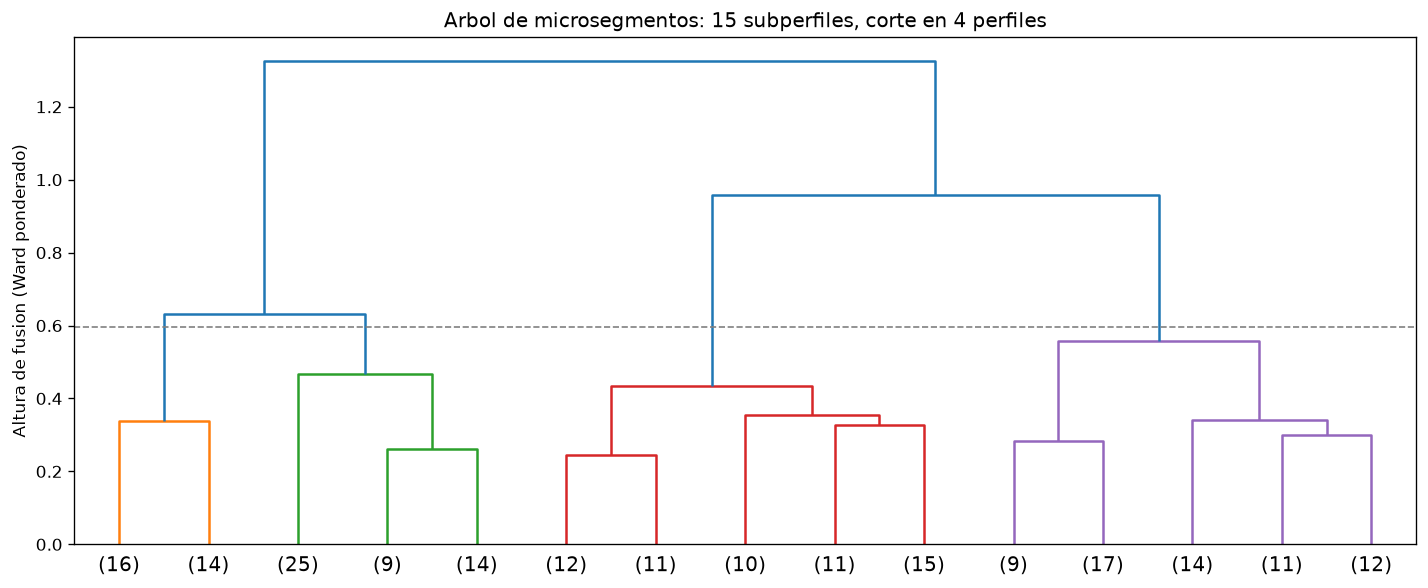

In [11]:
umbral = (alturas[K_MACRO - 2] + alturas[K_MACRO - 1]) / 2

fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(L, truncate_mode="lastp", p=K_SUB, color_threshold=umbral, show_leaf_counts=True, ax=ax)
ax.axhline(umbral, color="gray", linestyle="--", linewidth=1)
ax.set_title(f"Arbol de microsegmentos: {K_SUB} subperfiles, corte en {K_MACRO} perfiles")
ax.set_ylabel("Altura de fusion (Ward ponderado)")
plt.tight_layout()
plt.show()

## 6. Tres niveles

### 6.1 Asignacion

Cada celda hereda subperfil y perfil de su microsegmento. Los perfiles se numeran por promedio de
participacion (0 = menor), igual que en el notebook 04. Los subperfiles se numeran dentro de su
perfil, tambien por promedio (ej. 2.1, 2.2).

In [12]:
celdas["micro"] = micro
celdas["perfil_raw"] = cortar(L, K_MACRO)[micro]
celdas["sub_id"] = cortar(L, K_SUB)[micro]

orden = media_ponderada(celdas, "promedio", ["perfil_raw"]).sort_values().index
celdas["perfil"] = celdas["perfil_raw"].map({old: new for new, old in enumerate(orden)})

prom_sub = (
    media_ponderada(celdas, "promedio", ["perfil", "sub_id"])
    .rename("prom")
    .reset_index()
    .sort_values("prom")
)
prom_sub["subperfil"] = (
    prom_sub["perfil"].astype(str) + "." + (prom_sub.groupby("perfil").cumcount() + 1).astype(str)
)
celdas["subperfil"] = celdas["sub_id"].map(prom_sub.set_index("sub_id")["subperfil"])
celdas = celdas.drop(columns="perfil_raw")

celdas.groupby("perfil")["subperfil"].nunique().rename("subperfiles")

perfil
0    5
1    2
2    5
3    3
Name: subperfiles, dtype: int64

### 6.2 Resumen ponderado

Misma funcion para los tres niveles: personas, conducta (promedio, brecha, tendencia, PJ 2025),
composicion (% mujer, % rural o mixta, edad y region dominantes).

In [13]:
def resumen(df, por):
    personas = df.groupby(por)["peso"].sum()
    out = pd.DataFrame({"personas": personas, "pct_pob": personas / df["peso"].sum() * 100})
    for col in ["promedio", "brecha_pres", "tendencia", "P_PJ2025", "MUJER", "RURAL_MIXTA"]:
        out[col] = media_ponderada(df, col, por)
    out[["MUJER", "RURAL_MIXTA"]] *= 100
    out["edad_dominante"] = dominante(df, por, "GRUPO_EDAD")
    out["region_dominante"] = dominante(df, por, "REGION")
    return out.round(1)


resumen(celdas, ["perfil"])

,personas,pct_pob,promedio,brecha_pres,tendencia,P_PJ2025,MUJER,RURAL_MIXTA,edad_dominante,region_dominante
perfil,,,,,,,,,,
0,22530699,32.8,43.9,18.3,2.1,12.6,39.9,20.0,30-39,Centro
1,10006190,14.6,48.3,10.0,-1.4,10.3,43.0,34.2,30-39,Occidente
2,20237333,29.5,64.7,16.2,4.1,15.4,65.1,29.0,50-59,Centro
3,15832200,23.1,66.1,5.4,-0.3,12.7,59.7,43.6,50-59,Centro


### 6.3 Subperfiles

In [14]:
resumen(celdas, ["perfil", "subperfil"])

personas  pct_pob  promedio  brecha_pres  tendencia  \
perfil subperfil                                                        
0      0.1         3968183      5.8      36.5         16.3        0.3   
       0.2         4662525      6.8      39.7         17.1        3.6   
       0.3         4160370      6.1      44.2          8.6        1.6   
       0.4         7279268     10.6      48.0         21.9        1.9   
       0.5         2460353      3.6      50.6         29.5        3.9   
1      1.1         4440548      6.5      40.0          7.6       -1.8   
       1.2         5565642      8.1      55.0         12.0       -1.1   
2      2.1         5018241      7.3      56.3         13.6        4.0   
       2.2         2072459      3.0      61.4         23.1        7.4   
       2.3         4681150      6.8      62.9         22.0        3.0   
       2.4         4137063      6.0      70.4         16.4        4.3   
       2.5         4328420      6.3      72.6          9.2        3.4   
3      3.1         2820701      4.1      53.4         -0.3       -2.3   
       3.2        10350233     15.1      68.4          8.0        0.6   
       3.3         2661266      3.9      70.8          1.4       -1.8   

                  P_PJ2025  MUJER  RURAL_MIXTA edad_dominante region_dominante  
perfil subperfil                                                                
0      0.1            10.4   25.2         21.4          30-39           Centro  
       0.2            12.9   31.0         21.1          18-24           Centro  
       0.3            12.3   32.9         35.8          30-39        Occidente  
       0.4            13.1   49.3         13.2          30-39           Centro  
       0.5            14.2   64.4          8.7          30-39           Centro  
1      1.1             9.3   27.7         40.3          30-39        Occidente  
       1.2            11.1   55.1         29.3          40-49           Centro  
2      2.1            14.7   55.2         31.3          30-39           Centro  
       2.2            15.8   70.2         34.6          30-39           Centro  
       2.3            14.6   71.3         14.0          50-59           Centro  
       2.4            16.2   69.0         27.6          60-69           Centro  
       2.5            16.2   63.8         41.3          60-69           Centro  
3      3.1            10.6   42.1         52.5          30-39        Occidente  
       3.2            13.4   63.8         37.2          50-59           Centro  
       3.3            11.9   62.6         59.5          50-59           Centro

### 6.4 Trayectorias de los subperfiles

Un panel por perfil. Muestra si los subperfiles difieren en nivel, en forma o en ambos.

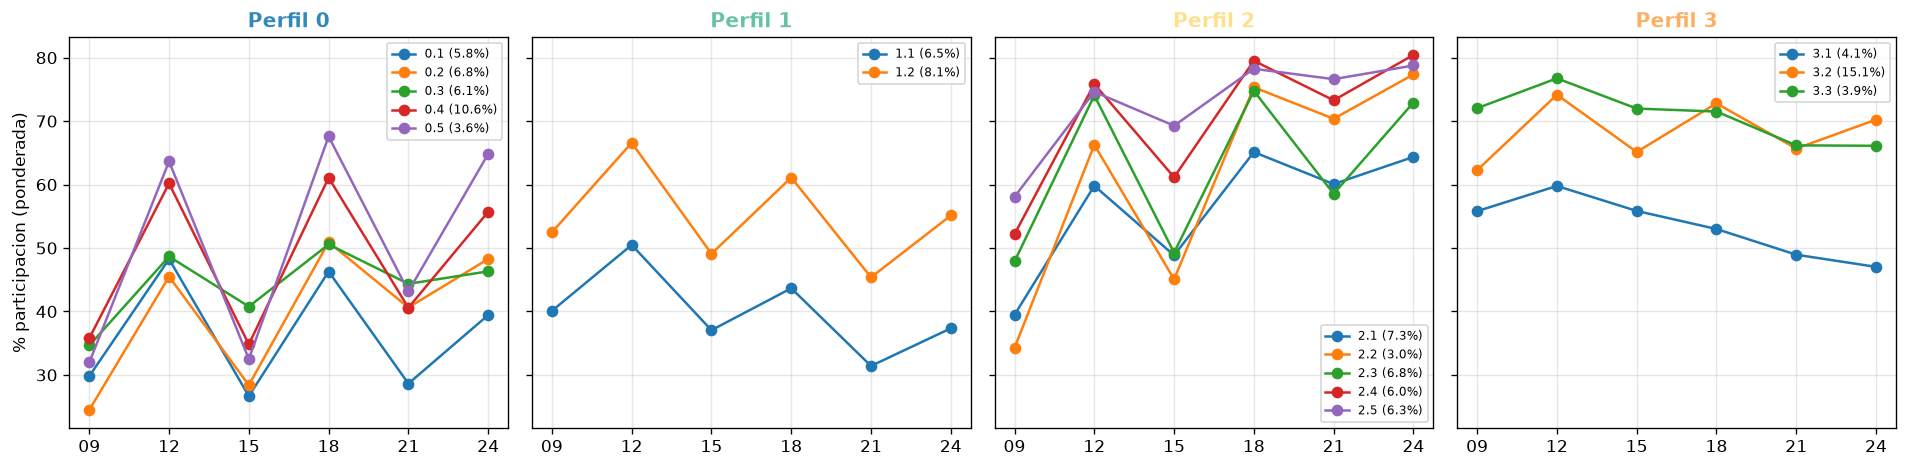

In [15]:
anos = [2009, 2012, 2015, 2018, 2021, 2024]
tray_sub = pd.DataFrame({e: media_ponderada(celdas, e, ["perfil", "subperfil"]) for e in ELECCIONES})
pct_sub = celdas.groupby(["perfil", "subperfil"])["peso"].sum() / celdas["peso"].sum() * 100

fig, axes = plt.subplots(1, K_MACRO, figsize=(4 * K_MACRO, 4), sharey=True)
for p, ax in enumerate(axes):
    for (pp, s), fila in tray_sub.loc[[p]].iterrows():
        ax.plot(anos, fila.to_numpy(), "o-", label=f"{s} ({pct_sub[(pp, s)]:.1f}%)")
    ax.set_title(f"Perfil {p}", color=COLORES_PERFIL[p], fontweight="bold")
    ax.set_xticks(anos, [str(a)[2:] for a in anos])
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
axes[0].set_ylabel("% participacion (ponderada)")
plt.tight_layout()
plt.show()

### 6.5 Tabla de microsegmentos

Base para microtargeting: cada microsegmento con su perfil, subperfil, tamano, conducta,
composicion y las 3 entidades donde tiene mas personas. Se muestran los 5 mas grandes por perfil.

In [16]:
tabla_micro = resumen(celdas, ["perfil", "subperfil", "micro"])

top_ent = (
    celdas.groupby(["micro", "EDOCVE"])["peso"].sum()
    .groupby(level="micro", group_keys=False).nlargest(3)
    .reset_index()
)
top_ent["entidad"] = top_ent["EDOCVE"].map(EDONOM)
tabla_micro = tabla_micro.join(top_ent.groupby("micro")["entidad"].agg(", ".join).rename("top_entidades"))

(tabla_micro.sort_values("personas", ascending=False)
 .groupby(level="perfil").head(5)
 .sort_index())

personas  pct_pob  promedio  brecha_pres  tendencia  \
perfil subperfil micro                                                        
0      0.2       73       581310      0.8      49.9         15.5        2.9   
       0.4       47       577672      0.8      56.4         18.4        2.0   
                 71       538857      0.8      49.7         19.9        2.5   
                 132      543524      0.8      43.7         17.6        1.8   
                 162      550665      0.8      50.5         17.7        1.1   
1      1.2       40       513156      0.7      49.3         15.0       -0.2   
                 81       534620      0.8      56.1         16.0        0.4   
                 85       517935      0.8      53.0         12.3       -1.0   
                 125      563610      0.8      53.2         11.6        0.7   
                 158      565430      0.8      60.7         13.4       -0.2   
2      2.1       30       544373      0.8      59.5         15.6        3.2   
                 112      575818      0.8      61.2         15.0        1.5   
       2.3       60       542836      0.8      63.6         19.0        2.1   
       2.4       4        600599      0.9      66.3         17.7        3.6   
                 166      621541      0.9      67.1         15.2        2.3   
3      3.2       17       570695      0.8      57.2          9.1       -0.2   
                 33       563684      0.8      67.2         14.6        0.8   
                 45       544822      0.8      66.7         10.3        0.3   
                 179      542059      0.8      72.5          9.8        1.2   
                 181      583688      0.9      65.9         11.0        1.9   

                        P_PJ2025  MUJER  RURAL_MIXTA edad_dominante  \
perfil subperfil micro                                                
0      0.2       73         14.0   46.8         21.7          30-39   
       0.4       47         14.0   56.0         15.1          40-49   
                 71         13.7   48.6         12.1          40-49   
                 132        12.8   37.8         14.6          30-39   
                 162        12.8   53.0         14.5          30-39   
1      1.2       40         11.4   51.6         19.0          30-39   
                 81         12.5   59.2         15.8          40-49   
                 85         10.7   54.9         25.5          30-39   
                 125        12.4   44.4         24.0          40-49   
                 158        12.1   63.9         21.0          40-49   
2      2.1       30         14.9   56.7         22.7          50-59   
                 112        13.6   61.2         18.7          50-59   
       2.3       60         14.4   68.0         15.4          50-59   
       2.4       4          15.1   63.1         16.2          50-59   
                 166        14.7   65.2         18.1          50-59   
3      3.2       17         11.6   49.7         32.1          40-49   
                 33         13.6   70.9         19.1          50-59   
                 45         12.9   65.6         27.2          50-59   
                 179        14.6   67.8         28.6          50-59   
                 181        14.2   61.1         25.4          50-59   

                       region_dominante                       top_entidades  
perfil subperfil micro                                                       
0      0.2       73              Centro         Mexico, Veracruz, Michoacan  
       0.4       47              Centro  Mexico, Ciudad de Mexico, Veracruz  
                 71              Centro  Mexico, Ciudad de Mexico, Veracruz  
                 132             Centro   Mexico, Baja California, Veracruz  
                 162             Centro   Mexico, Veracruz, Baja California  
1      1.2       40              Centro         Mexico, Jalisco, Guanajuato  
                 81              Centro         Mexico, Jalisco, Guanajuato  
                 85 

### 6.6 Mapa de microsegmentos

Cada burbuja es un microsegmento, con tamano proporcional a las personas que representa.

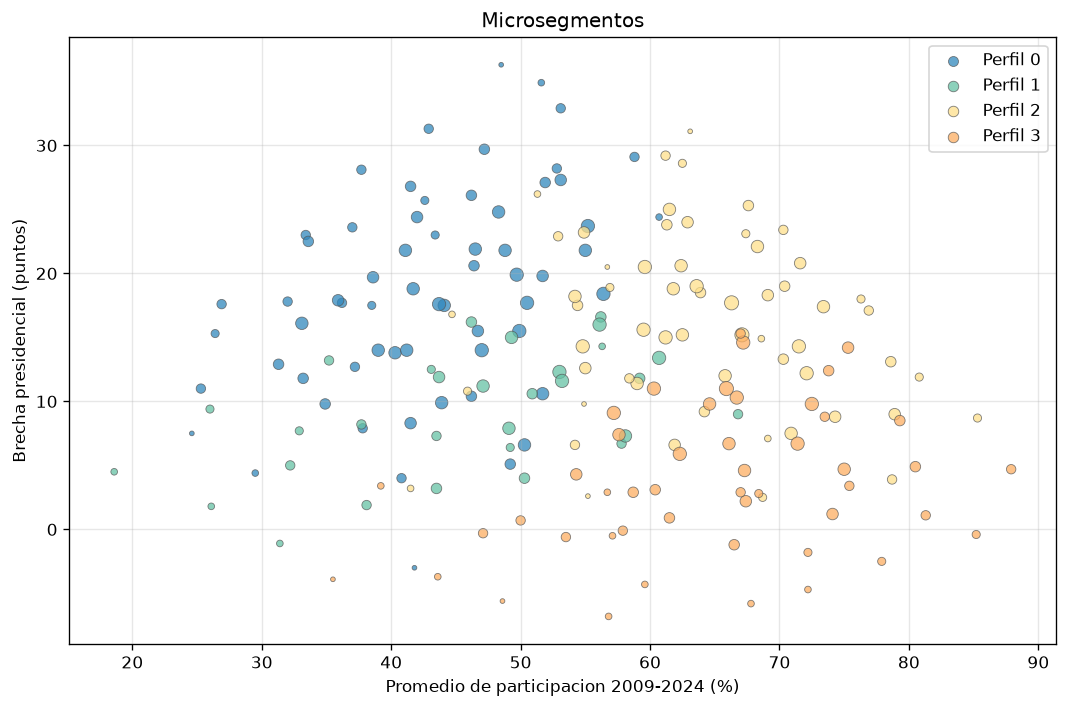

In [17]:
t = tabla_micro.reset_index()

fig, ax = plt.subplots(figsize=(9, 6))
for p, d in t.groupby("perfil"):
    ax.scatter(d["promedio"], d["brecha_pres"], s=d["pct_pob"] * 80, color=COLORES_PERFIL[p],
               alpha=0.75, edgecolor="#555", linewidth=0.5, label=f"Perfil {p}")
ax.set_xlabel("Promedio de participacion 2009-2024 (%)")
ax.set_ylabel("Brecha presidencial (puntos)")
ax.set_title("Microsegmentos")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Estabilidad y comparacion

### 7.1 Bootstrap

Bootstrap de Poisson: el peso de cada celda se multiplica por un Poisson(1), equivalente a
remuestrear personas con reemplazo. Se repiten microsegmentos y arbol, y se compara contra la
solucion original con ARI en la muestra eval.

In [18]:
filas = []
for b in range(N_BOOT):
    w_b = w * np.random.default_rng(1000 + b).poisson(1.0, size=len(w))
    km_b = KMeans(N_MICRO, n_init=3, random_state=1000 + b).fit(Z, sample_weight=w_b)
    p_b = np.bincount(km_b.labels_, weights=w_b, minlength=N_MICRO) + 1e-9
    L_b = ward_ponderado(km_b.cluster_centers_, p_b)
    micro_eval = km_b.labels_[idx_eval]
    filas.append({
        "replica": b + 1,
        "ari_perfil": adjusted_rand_score(celdas["perfil"].to_numpy()[idx_eval],
                                          cortar(L_b, K_MACRO)[micro_eval]),
        "ari_subperfil": adjusted_rand_score(celdas["sub_id"].to_numpy()[idx_eval],
                                             cortar(L_b, K_SUB)[micro_eval]),
    })
estabilidad = pd.DataFrame(filas)
print(f"ARI medio perfil: {estabilidad['ari_perfil'].mean():.3f}  "
      f"subperfil: {estabilidad['ari_subperfil'].mean():.3f}")
estabilidad.round(3)

ARI medio perfil: 0.328  subperfil: 0.273


,replica,ari_perfil,ari_subperfil
0,1,0.332,0.272
1,2,0.292,0.254
2,3,0.359,0.293


### 7.2 Comparacion con modelos previos

ARI de los perfiles contra el modelo del notebook 04 y los finalistas del 05, si existe
`celdas_perfiles_candidatos.parquet`.

In [19]:
ruta = DIR_PREPROCESSED / "celdas_perfiles_candidatos.parquet"
if ruta.exists():
    llaves = ["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"]
    previos = celdas[llaves + ["perfil"]].merge(
        pd.read_parquet(ruta).drop(columns="peso"), on=llaves, how="left"
    )
    for col in [c for c in previos.columns if c.startswith(("base_", "candidato_"))]:
        otro = previos[col].fillna(-1).astype(int).to_numpy()[idx_eval]
        ari = adjusted_rand_score(previos["perfil"].to_numpy()[idx_eval], otro)
        print(f"ARI vs {col}: {ari:.3f}")
else:
    print("Sin resultados del notebook 05 para comparar.")

ARI vs base_04: 0.331
ARI vs candidato_1: 0.207
ARI vs candidato_2: 0.204
ARI vs candidato_3: 0.206


## 8. Territorio

Para cada municipio: microsegmento con mas personas (y su subperfil y perfil), su porcentaje
dentro del municipio y la distribucion de perfiles. Sirve para asignar campanas por territorio.

In [20]:
llave_mpio = ["EDOCVE", "MPIOCVE"]
mpio = celdas.groupby(llave_mpio + ["MPIONOM", "micro"])["peso"].sum().reset_index()
mpio["pct_micro"] = mpio["peso"] / mpio.groupby(llave_mpio)["peso"].transform("sum") * 100
municipios = mpio.loc[mpio.groupby(llave_mpio)["peso"].idxmax()].copy()

niveles = celdas.drop_duplicates("micro").set_index("micro")[["perfil", "subperfil"]]
municipios = municipios.join(niveles, on="micro")

dist = celdas.groupby(llave_mpio + ["perfil"])["peso"].sum().unstack(fill_value=0)
dist = (dist.div(dist.sum(axis=1), axis=0) * 100).round(1).add_prefix("pct_perfil_")
municipios = municipios.join(dist, on=llave_mpio)
municipios["entidad"] = municipios["EDOCVE"].map(EDONOM)
municipios = municipios.rename(columns={"peso": "personas_micro"})

print(f"Municipios: {len(municipios):,}")
municipios.sort_values("pct_micro", ascending=False).head(10)

Municipios: 2,360


,EDOCVE,MPIOCVE,MPIONOM,micro,personas_micro,pct_micro,perfil,subperfil,pct_perfil_0,pct_perfil_1,pct_perfil_2,pct_perfil_3,entidad
70866,20,377,Santa Cruz de Bravo,142,49,100.00000,0,0.3,100.0,0.0,0.0,0.0,Oaxaca
65858,20,111,San Baltazar Yatzachi el Bajo,56,20,100.00000,0,0.4,100.0,0.0,0.0,0.0,Oaxaca
74976,20,556,La Trinidad Vista Hermosa,63,22,100.00000,1,1.2,0.0,100.0,0.0,0.0,Oaxaca
69149,20,285,San Miguel Tulancingo,137,24,100.00000,1,1.1,0.0,100.0,0.0,0.0,Oaxaca
74072,20,524,Santo Domingo Yodohino,32,23,100.00000,3,3.1,0.0,0.0,0.0,100.0,Oaxaca
72679,20,464,Santiago Huauclilla,151,27,100.00000,0,0.4,100.0,0.0,0.0,0.0,Oaxaca
66406,20,148,San Francisco Teopan,153,21,100.00000,2,2.5,0.0,0.0,100.0,0.0,Oaxaca
70034,20,329,San Pedro Tidaá,198,36,100.00000,0,0.4,100.0,0.0,0.0,0.0,Oaxaca
65956,20,119,San Bartolomé Zoogocho,114,23,100.00000,1,1.1,0.0,100.0,0.0,0.0,Oaxaca
13985,8,54,Riva Palacio,193,4471,96.17122,0,0.2,98.1,0.0,1.9,0.0,Chihuahua


## 9. Exportacion

No se sobrescribe nada de los notebooks 04-06.

In [21]:
salidas = {
    "celdas_jerarquia.parquet": celdas[["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD", "peso",
                                         "micro", "subperfil", "perfil"]],
    "jerarquia_perfiles.csv": resumen(celdas, ["perfil"]),
    "jerarquia_subperfiles.csv": resumen(celdas, ["perfil", "subperfil"]),
    "jerarquia_microsegmentos.csv": tabla_micro,
    "jerarquia_municipios.csv": municipios,
}
for nombre, df in salidas.items():
    ruta = DIR_PREPROCESSED / nombre
    if nombre.endswith(".parquet"):
        df.to_parquet(ruta, index=False)
    else:
        df.to_csv(ruta, index=nombre != "jerarquia_municipios.csv")
    print(f"{nombre}: {ruta.stat().st_size / 1024:.0f} KB")

celdas_jerarquia.parquet: 2353 KB
jerarquia_perfiles.csv: 0 KB
jerarquia_subperfiles.csv: 1 KB
jerarquia_microsegmentos.csv: 19 KB
jerarquia_municipios.csv: 184 KB
